In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\mahar\Downloads\Food_Delivery_Orders_2025.csv")

In [3]:
df1=df.copy()

In [4]:
df1

,Order_ID,Order_Date,Order_Time,Customer_Name,City,Cuisine,Restaurant_Type,Payment_Mode,Order_Amount,Discount,Delivery_Time_Min,Customer_Rating,Order_Status
0,ORD1566,2025-06-18,20:31,Pooja Kumar,Mumbai,Fast Food,Restaurant,Credit Card,202.0,40.0,27.0,4.0,Delivered
1,ORD1462,2025-01-30,19:23,priya das,Delhi,North Indian,Cafe,Cash on Delivery,266.0,53.0,NaN,NaN,Cancelled
2,ORD1581,2025-09-16,13:38,Deepa Rao,Delhi,Chinese,Restaurant,COD,198.0,30.0,43.0,NaN,Delivered
3,ORD1544,2025-12-24,21:16,Arjun Nair,Mumbai,Biryani,Restaurant,Upi,NaN,51.0,51.0,3.0,Delivered
4,ORD1222,2025-05-02,19:53,sneha iyer,hyderabad,North Indian,Cloud Kitchen,Debit Card,450.0,68.0,36.0,5.0,Delivered
...,...,...,...,...,...,...,...,...,...,...,...,...,...
620,ORD1333,2025-02-18,19:31,isha joshi,Delhi,South Indian,Restaurant,UPI,219.0,44.0,39.0,NaN,Delivered
621,ORD1270,2025-10-14,20:53,vikram singh,Mumbai,Desserts,Cafe,Cash on Delivery,NaN,0.0,NaN,NaN,Cancelled
622,ORD1338,2025-04-19,17:22,PRIYA SINGH,Bengaluru,Biryani,Cloud Kitchen,Credit Card,581.0,87.0,47.0,NaN,Delivered
623,ORD1092,2025-09-24,20:02,Karthik Gupta,Delhi,Fast Food,Restaurant,UPI,152.0,30.0,35.0,5.0,Delivered


#understand the data

In [5]:
print('shape \n',df1.shape)

shape 
 (625, 13)


In [6]:
df1.head()

,Order_ID,Order_Date,Order_Time,Customer_Name,City,Cuisine,Restaurant_Type,Payment_Mode,Order_Amount,Discount,Delivery_Time_Min,Customer_Rating,Order_Status
0,ORD1566,2025-06-18,20:31,Pooja Kumar,Mumbai,Fast Food,Restaurant,Credit Card,202.0,40.0,27.0,4.0,Delivered
1,ORD1462,2025-01-30,19:23,priya das,Delhi,North Indian,Cafe,Cash on Delivery,266.0,53.0,NaN,NaN,Cancelled
2,ORD1581,2025-09-16,13:38,Deepa Rao,Delhi,Chinese,Restaurant,COD,198.0,30.0,43.0,NaN,Delivered
3,ORD1544,2025-12-24,21:16,Arjun Nair,Mumbai,Biryani,Restaurant,Upi,NaN,51.0,51.0,3.0,Delivered
4,ORD1222,2025-05-02,19:53,sneha iyer,hyderabad,North Indian,Cloud Kitchen,Debit Card,450.0,68.0,36.0,5.0,Delivered


In [7]:
df1.tail()

,Order_ID,Order_Date,Order_Time,Customer_Name,City,Cuisine,Restaurant_Type,Payment_Mode,Order_Amount,Discount,Delivery_Time_Min,Customer_Rating,Order_Status
620,ORD1333,2025-02-18,19:31,isha joshi,Delhi,South Indian,Restaurant,UPI,219.0,44.0,39.0,NaN,Delivered
621,ORD1270,2025-10-14,20:53,vikram singh,Mumbai,Desserts,Cafe,Cash on Delivery,NaN,0.0,NaN,NaN,Cancelled
622,ORD1338,2025-04-19,17:22,PRIYA SINGH,Bengaluru,Biryani,Cloud Kitchen,Credit Card,581.0,87.0,47.0,NaN,Delivered
623,ORD1092,2025-09-24,20:02,Karthik Gupta,Delhi,Fast Food,Restaurant,UPI,152.0,30.0,35.0,5.0,Delivered
624,ORD1081,28-Aug-2025,13:56,Rahul Sharma,Pune,Biryani,Cloud Kitchen,WALLET,357.0,54.0,NaN,5.0,Delivered


In [8]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 625 entries, 0 to 624
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           625 non-null    object 
 1   Order_Date         621 non-null    object 
 2   Order_Time         625 non-null    object 
 3   Customer_Name      625 non-null    object 
 4   City               625 non-null    object 
 5   Cuisine            625 non-null    object 
 6   Restaurant_Type    625 non-null    object 
 7   Payment_Mode       625 non-null    object 
 8   Order_Amount       600 non-null    float64
 9   Discount           607 non-null    float64
 10  Delivery_Time_Min  569 non-null    float64
 11  Customer_Rating    498 non-null    float64
 12  Order_Status       625 non-null    object 
dtypes: float64(4), object(9)
memory usage: 63.6+ KB


In [9]:
miss=df1.isnull().sum()
miss
missing_report=pd.DataFrame({'missing':miss,'percent':(miss / len(df1)*100).round(2)})
missing_report
missing_report[missing_report['missing']>0].sort_values('missing',ascending=False)

,missing,percent
Customer_Rating,127,20.32
Delivery_Time_Min,56,8.96
Order_Amount,25,4.00
Discount,18,2.88
Order_Date,4,0.64


In [10]:
print('duplicateds rows:',df1.duplicated().sum())
df1[df1.duplicated(keep=False)].sort_values('Order_ID').head(6)

duplicateds rows: 25


,Order_ID,Order_Date,Order_Time,Customer_Name,City,Cuisine,Restaurant_Type,Payment_Mode,Order_Amount,Discount,Delivery_Time_Min,Customer_Rating,Order_Status
480,ORD1054,19-May-2025,12:51,Rahul Joshi,Hyderabad,Chinese,Restaurant,Debit Card,261.0,0.0,34.0,5.0,Delivered
135,ORD1054,19-May-2025,12:51,Rahul Joshi,Hyderabad,Chinese,Restaurant,Debit Card,261.0,0.0,34.0,5.0,Delivered
197,ORD1061,2025-06-15,19:38,Rahul Joshi,Mumbai,North Indian,Cloud Kitchen,Cash on Delivery,378.0,38.0,30.0,5.0,Delivered
31,ORD1061,2025-06-15,19:38,Rahul Joshi,Mumbai,North Indian,Cloud Kitchen,Cash on Delivery,378.0,38.0,30.0,5.0,Delivered
405,ORD1098,2025-08-10,13:36,Priya Patel,mumbai,Fast Food,Cloud Kitchen,Credit Card,562.0,56.0,40.0,3.0,Delivered
28,ORD1098,2025-08-10,13:36,Priya Patel,mumbai,Fast Food,Cloud Kitchen,Credit Card,562.0,56.0,40.0,3.0,Delivered


In [11]:
display(df1.describe().round(2))
print("Negative / zero Order_Amount :", (df["Order_Amount"] <= 0).sum())
print("Order_Amount above 5000      :", (df["Order_Amount"] > 5000).sum())
print("Delivery time < 10 or > 120  :", (~df["Delivery_Time_Min"].dropna().between(10, 120)).sum())
print("Rating outside 1 to 5        :", (~df["Customer_Rating"].dropna().between(1, 5)).sum())
print("Unparseable-looking dates    :", df["Order_Date"].isin(["Not Available", "N/A", ""]).sum(), "(plus blanks read as NaN)")

,Order_Amount,Discount,Delivery_Time_Min,Customer_Rating
count,600.00,607.00,569.00,498.00
mean,668.47,30.63,38.02,4.30
std,4437.93,30.55,41.18,0.78
min,-430.00,0.00,0.00,0.00
25%,273.75,0.00,31.00,4.00
50%,346.00,24.00,37.00,4.00
75%,447.50,52.00,42.00,5.00
max,99999.00,148.00,999.00,9.00


Negative / zero Order_Amount : 5
Order_Amount above 5000      : 5
Delivery time < 10 or > 120  : 4
Rating outside 1 to 5        : 4
Unparseable-looking dates    : 1 (plus blanks read as NaN)


Data cleaning

In [12]:
# B1 Remove duplicate rows. Print the row count before and after

In [13]:
before = len(df1)
df1 = df1.drop_duplicates()
print('Rows before:', before,
      '| Rows After:', len(df1),
      '| Removed:', before - len(df1))

Rows before: 625 | Rows After: 600 | Removed: 25


# B2 Customer_Name has extra spaces and mixed upper/lower case. Make every name clean, e.g. Rahul Sharma.

In [14]:
df1['Customer_Name']=df1['Customer_Name'].str.strip().str.title()
df1['Customer_Name'].sample(8,random_state=1).tolist()

C:\Users\mahar\AppData\Local\Temp\ipykernel_24044\1360302272.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Customer_Name']=df1['Customer_Name'].str.strip().str.title()


['Meena Gupta',
 'Manoj Iyer',
 'Nikhil Nair',
 'Kavya Rao',
 'Aditya Sharma',
 'Divya Iyer',
 'Kavya Singh',
 'Divya Joshi']

# B3 City has the same city written in many ways (spelling, case, spaces, old names). Print unique values,
# then standardise to exactly 6 cities

In [15]:
df1['City'].unique()

array(['Mumbai', 'Delhi', 'hyderabad', 'delhi', 'Hyderabad', 'Chennai',
       'New Delhi', 'mumbai', 'Pune', 'Bengaluru', 'Bangalore', 'chennai',
       'bangalore', 'MUMBAI', 'CHENNAI', 'HYDERABAD ', ' Pune', 'PUNE',
       'Chennai ', 'DELHI', 'BENGALURU', 'Bombay', 'Hyd', 'pune'],
      dtype=object)

In [16]:
print('Before:',sorted(df1['City'].unique()))
df1['City']=df1['City'].str.strip().str.title()

Before: [' Pune', 'BENGALURU', 'Bangalore', 'Bengaluru', 'Bombay', 'CHENNAI', 'Chennai', 'Chennai ', 'DELHI', 'Delhi', 'HYDERABAD ', 'Hyd', 'Hyderabad', 'MUMBAI', 'Mumbai', 'New Delhi', 'PUNE', 'Pune', 'bangalore', 'chennai', 'delhi', 'hyderabad', 'mumbai', 'pune']


C:\Users\mahar\AppData\Local\Temp\ipykernel_24044\2843862073.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['City']=df1['City'].str.strip().str.title()


In [17]:
city_map = {
    'New Delhi': 'Delhi',
    'Bangalore': 'Bengaluru',
    'Bombay': 'Mumbai',
    'Hyd': 'Hyderabad'
}

In [18]:
df1['City']=df1['City'].replace(city_map)
print('After:',sorted(df1['City'].unique()))
df1['City'].value_counts()

After: ['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Mumbai', 'Pune']


C:\Users\mahar\AppData\Local\Temp\ipykernel_24044\3750057348.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['City']=df1['City'].replace(city_map)


City
Bengaluru    136
Mumbai       122
Chennai       97
Hyderabad     91
Delhi         88
Pune          66
Name: count, dtype: int64

payment mode

In [19]:
print('Before:',sorted(df1['Payment_Mode'].unique()))

Before: ['CC', 'COD', 'Cash on Delivery', 'Credit Card', 'Credit card', 'DC', 'Debit Card', 'UPI', 'UPI ', 'Upi', 'WALLET', 'Wallet', 'cash on delivery', 'cod', 'credit card', 'debit card', 'upi', 'wallet']


In [20]:
df1['Payment_Mode']=df1['Payment_Mode'].str.strip().str.title()
df1['Payment_Mode'].unique()

C:\Users\mahar\AppData\Local\Temp\ipykernel_24044\1729382899.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Payment_Mode']=df1['Payment_Mode'].str.strip().str.title()


array(['Credit Card', 'Cash On Delivery', 'Cod', 'Upi', 'Debit Card',
       'Wallet', 'Dc', 'Cc'], dtype=object)

In [21]:
Payment_Method={
    'Cod':'Cash On Delivery',
    'Dc':'Debit Card',
    'Cc':'Credit Card',
    'Upi':'UPI'  
}

In [22]:
df1['Payment_Mode']=df1['Payment_Mode'].replace(Payment_Method)

C:\Users\mahar\AppData\Local\Temp\ipykernel_24044\863800132.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Payment_Mode']=df1['Payment_Mode'].replace(Payment_Method)


In [23]:
print('Unmapped values:',df1['Payment_Mode'].isnull().sum())
print('After:',sorted(df1['Payment_Mode'].unique()))
df1['Payment_Mode'].value_counts()

Unmapped values: 0
After: ['Cash On Delivery', 'Credit Card', 'Debit Card', 'UPI', 'Wallet']


Payment_Mode
UPI                 284
Cash On Delivery    119
Credit Card          95
Debit Card           62
Wallet               40
Name: count, dtype: int64

Cuisine

In [24]:
print('Befor:',df1['Cuisine'].nunique(), 'unique->',sorted(df1['Cuisine'].unique()))

Befor: 20 unique-> ['BIRYANI', 'Biryani', 'CHINESE', 'Chinese', 'DESSERTS', 'Desserts', 'FAST FOOD', 'Fast Food', 'HEALTHY', 'Healthy', 'NORTH INDIAN', 'North Indian', 'SOUTH INDIAN', 'South Indian', 'chinese', 'desserts', 'fast food', 'healthy', 'north indian', 'south indian']


In [25]:
df1['Cuisine']=df1['Cuisine'].str.strip().str.title()

C:\Users\mahar\AppData\Local\Temp\ipykernel_24044\599415960.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['Cuisine']=df1['Cuisine'].str.strip().str.title()


In [26]:
print('After:',df1['Cuisine'].nunique(),'unique->',sorted(df1['Cuisine'].unique()))

After: 7 unique-> ['Biryani', 'Chinese', 'Desserts', 'Fast Food', 'Healthy', 'North Indian', 'South Indian']


order data

In [27]:
df1["Order_Date"] = pd.to_datetime(df1["Order_Date"],format="mixed",errors="coerce")

C:\Users\mahar\AppData\Local\Temp\ipykernel_24044\345804879.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1["Order_Date"] = pd.to_datetime(df1["Order_Date"],format="mixed",errors="coerce")


In [28]:
invalid_dates = df1["Order_Date"].isna().sum()

In [29]:
print("Invalid dates:", invalid_dates) #4 nan values is there so if we delete customer data also detele we keep that data
df1=df1.dropna(subset=['Order_Date'])
print('Rows left:',len(df1),'| Date Range:',df1['Order_Date'].min().date(),'to',df1['Order_Date'].max().date())

Invalid dates: 4
Rows left: 596 | Date Range: 2025-01-01 to 2025-12-31


order amount

In [30]:
#Calculate IQR boundaries for the 'Order_Amount' column
Q1 = df1['Order_Amount'].quantile(0.25)
Q3 = df1['Order_Amount'].quantile(0.75)
IQR = Q3 - Q1

In [31]:
# Define outlier thresholds (Extreme outliers use 3 * IQR, standard uses 1.5 * IQR)
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

In [32]:
# Identify the conditions for invalid data
negative = df1['Order_Amount'] < 0
outlier = (df1['Order_Amount'] < lower) | (df1['Order_Amount'] > upper)

In [33]:
#Report the findings
print("Negative values:",negative.sum())
print("Outliers values:",outlier.sum())

Negative values: 5
Outliers values: 17


In [34]:
#Mark them as missing (NaN)
df1.loc[negative | outlier, 'Order_Amount'] = np.nan
print('order_amount missing value:',df1['Order_Amount'].isnull().sum(),'|max amount:',df1['Order_Amount'].max())

order_amount missing value: 41 |max amount: 703.0


In [35]:
# Fill missing Order_Amount values with the median of their specific Cuisine group
df1['Order_Amount'] = df1['Order_Amount'].fillna(
    df1.groupby('Cuisine')['Order_Amount'].transform('median'))
print('missing order_amount:',df1['Order_Amount'].isnull().sum())
df1.groupby('Cuisine')['Order_Amount'].median().round(0)

missing order_amount: 0


Cuisine
Biryani         396.0
Chinese         332.0
Desserts        201.0
Fast Food       301.0
Healthy         420.0
North Indian    436.0
South Indian    293.0
Name: Order_Amount, dtype: float64

discount

In [36]:
print('missing discount:',df1['Discount'].isnull().sum())
df1["Discount"] = df1["Discount"].fillna(df1["Discount"].median())
print('missing discount now:',df1['Discount'].isnull().sum())

missing discount: 18
missing discount now: 0


In [37]:
# Mark impossible delivery times as missing (0 or very large)
df1["Delivery_Time_Min"] = df1["Delivery_Time_Min"].mask(
    (df1["Delivery_Time_Min"] <= 0) | (df1["Delivery_Time_Min"] > 180)
)

In [38]:
# City-wise median (computed after removing impossible values)
city_median = df1.groupby('City')["Delivery_Time_Min"].transform("median")

In [39]:
# Fill missing values, but NOT for Cancelled orders
fill_mask = df1["Delivery_Time_Min"].isna() & (df1["Order_Status"] != "Cancelled")
df1.loc[fill_mask, "Delivery_Time_Min"] = city_median[fill_mask]

In [40]:
# Fill missing values ONLY for active orders using the city medians
# df1['Delivery_Time_Min'] = df1['Delivery_Time_Min'].fillna(city_medians)

In [41]:
df1['Delivery_Time_Min'].unique()

array([27., nan, 43., 51., 36., 25., 37., 31., 40., 38., 45., 34., 33.,
       56., 30., 44., 42., 32., 28., 26., 35., 21., 46., 29., 50., 41.,
       39., 53., 48., 24., 55., 20., 23., 13., 47., 22., 15., 49., 17.,
       54., 19., 57., 60., 52., 58.])

In [42]:
print('still missing:',df1["Delivery_Time_Min"].isna().sum(),'| all of them Cancelled?',
     (df1.loc[df1['Delivery_Time_Min'].isnull(),'Order_Status'] == 'Cancelled').all())  # should be 34
 # should show only Cancelled

still missing: 34 | all of them Cancelled? True


customer rating

In [43]:
# Customer_Rating: values outside 1 to 5 are invalid - mark them missing. Should you fill the missing
# ratings? Decide and justify in one line.
# df1['Customer_Rating'].isna().sum()

In [44]:
invalid_ratings = (df1['Customer_Rating'] < 1) | (df1['Customer_Rating'] > 5)
df1.loc[invalid_ratings, 'Customer_Rating'] = np.nan

In [45]:
print('missing ratings (kept as NaN:',df1['Customer_Rating'].isnull().sum(),'of',len(df1))
print('rating values now:', sorted(df1['Customer_Rating'].dropna().unique()))

missing ratings (kept as NaN: 122 of 596
rating values now: [np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


final amount

In [46]:
# Create Final_Amount = Order_Amount - Discount and Discount_Percent = Discount /
# Order_Amount x 100.

In [47]:
df1['Final_Amount'] = df1['Order_Amount']-df1['Discount']

In [48]:
df1['Discount_Percent'] = (df1['Discount'] / df1['Order_Amount'] * 100).round(1)
df1[['Order_Amount','Discount','Final_Amount','Discount_Percent']].describe().round(1)

,Order_Amount,Discount,Final_Amount,Discount_Percent
count,596.0,596.0,596.0,596.0
mean,364.1,30.0,334.1,8.3
std,119.1,30.1,114.0,7.5
min,118.0,0.0,112.0,0.0
25%,279.0,0.0,254.0,0.0
50%,346.0,23.0,321.0,6.0
75%,436.0,51.0,400.0,15.0
max,703.0,148.0,703.0,33.9


final check before and after table, save cleaned file

In [49]:
df1 = df1.reset_index(drop=True)
print("Shape:", df1.shape, "| Duplicates:", df1.duplicated().sum())
display(df1.isnull().sum()[df1.isnull().sum() > 0].to_frame("still_missing"))

summary = pd.DataFrame({
    "Issue": ["Rows", "Duplicate rows", "City spellings", "Payment_Mode spellings", "Cuisine spellings",
              "Invalid dates", "Negative Order_Amount", "Missing Order_Amount", "Delivery time invalid/missing (non-cancelled)"],
    "Before": [len(df), df.duplicated().sum(), df["City"].nunique(), df["Payment_Mode"].nunique(), df["Cuisine"].nunique(),
               pd.to_datetime(df["Order_Date"], format="mixed", dayfirst=True, errors="coerce").isnull().sum(),
               (df["Order_Amount"] <= 0).sum(), df["Order_Amount"].isnull().sum(),
               ((df["Order_Status"] != "Cancelled") & (df["Delivery_Time_Min"].isnull() | ~df["Delivery_Time_Min"].between(10, 120))).sum()],
    "After":  [len(df1), df1.duplicated().sum(), df1["City"].nunique(), df1["Payment_Mode"].nunique(), df1["Cuisine"].nunique(),
               df1["Order_Date"].isnull().sum(), (df1["Order_Amount"] <= 0).sum(), df1["Order_Amount"].isnull().sum(),
               ((df1["Order_Status"] != "Cancelled") & df1["Delivery_Time_Min"].isnull()).sum()]})
display(summary)
df1.to_csv("Food_Delivery_Cleaned.csv", index=False)
print("Saved: Food_Delivery_Cleaned.csv")

Shape: (596, 15) | Duplicates: 0


,still_missing
Delivery_Time_Min,34
Customer_Rating,122


,Issue,Before,After
0,Rows,625,596
1,Duplicate rows,25,0
2,City spellings,24,6
3,Payment_Mode spellings,18,5
4,Cuisine spellings,20,7
5,Invalid dates,5,0
6,Negative Order_Amount,5,0
7,Missing Order_Amount,25,0
8,Delivery time invalid/missing (non-cancelled),26,0


Saved: Food_Delivery_Cleaned.csv


# Datatime feature engineering

create new columns order date and order time

### C1-C9. Year, Month, Month_Name, Day, Day_Name, Weekday_No, Is_Weekend, Quarter, Week.

In [50]:
df1['Year'] = df1['Order_Date'].dt.year
df1['Month'] = df1['Order_Date'].dt.month
df1['Month_Name'] = df1['Order_Date'].dt.month_name()
df1['Day'] = df1['Order_Date'].dt.day
df1['Day_Name'] = df1['Order_Date'].dt.day_name()
df1['Weekday_No'] = df1['Order_Date'].dt.weekday
df1['Is_Weekend'] = np.where(df1['Weekday_No'] >= 5,'Weekend', 'Weekday')
df1['Quarter'] = df1['Order_Date'].dt.quarter
df1['Week'] = df1['Order_Date'].dt.isocalendar().week.astype(int)
df1[['Order_Date','Year','Month','Month_Name','Day','Day_Name','Weekday_No','Is_Weekend','Quarter','Week']].head(8)

,Order_Date,Year,Month,Month_Name,Day,Day_Name,Weekday_No,Is_Weekend,Quarter,Week
0,2025-06-18,2025,6,June,18,Wednesday,2,Weekday,2,25
1,2025-01-30,2025,1,January,30,Thursday,3,Weekday,1,5
2,2025-09-16,2025,9,September,16,Tuesday,1,Weekday,3,38
3,2025-12-24,2025,12,December,24,Wednesday,2,Weekday,4,52
4,2025-05-02,2025,5,May,2,Friday,4,Weekday,2,18
5,2025-10-04,2025,10,October,4,Saturday,5,Weekend,4,40
6,2025-03-02,2025,3,March,2,Sunday,6,Weekend,1,9
7,2025-04-30,2025,4,April,30,Wednesday,2,Weekday,2,18


#### c10-c11 hour from order_time and time_slot

In [51]:
df1['Hour'] = pd.to_datetime(df1['Order_Time'],format='%H:%M').dt.hour
conditions = [df1['Hour'].between(6,10),df1['Hour'].between(11,14), df1['Hour'].between(15,18), df1['Hour'].between(19,22)]
df1['Time_Slot'] = np.select(conditions,['Breakfast','Lunch','Snacks','Dinner'],default='Late Night')
display(df1[['Order_Time','Hour','Time_Slot']].sample(8,random_state=3))
print(df1.groupby('Time_Slot')['Hour'].agg(['min','max']))

,Order_Time,Hour,Time_Slot
192,13:43,13,Lunch
449,21:21,21,Dinner
112,08:35,8,Breakfast
10,12:25,12,Lunch
516,19:14,19,Dinner
330,17:58,17,Snacks
334,13:28,13,Lunch
127,09:35,9,Breakfast


            min  max
Time_Slot           
Breakfast     8    9
Dinner       19   21
Late Night    0   23
Lunch        12   13
Snacks       16   17


### c12 Days_since_first

In [52]:
df1['Days_Since_First'] = (df1['Order_Date'] - df1['Order_Date'].min()).dt.days
df1[['Order_Date','Days_Since_First']].sort_values('Days_Since_First').iloc[[0,1,-2,-1]]

,Order_Date,Days_Since_First
211,2025-01-01,0
516,2025-01-03,2
52,2025-12-31,364
397,2025-12-31,364


### c13 first order, last order, span, and orders on the 1st of any month

In [53]:
First, Last = df1['Order_Date'].min(), df1['Order_Date'].max()
print('First order:', First.date(),'| Lasr order:', Last.date(), '|span:',(Last - First),'Days')
print('Orders places on the 1st of a month:', (df1['Day'] == 1).sum())

First order: 2025-01-01 | Lasr order: 2025-12-31 |span: 364 days 00:00:00 Days
Orders places on the 1st of a month: 17


In [54]:
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
day_order   = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
slot_order  = ["Breakfast", "Lunch", "Snacks", "Dinner", "Late Night"]
delivered   = df[df["Order_Status"] == "Delivered"]

# Groupby Analysis

### d1 total orders and revenue per month_name in calendar order

In [55]:
d1 = df1.groupby('Month_Name').agg(orders=('Order_ID','count'), revenue=('Final_Amount','sum')).reindex(month_order)
display(d1.round(0))
print('Highest revenue:', d1['revenue'].idxmax(),round(d1['revenue'].max()),"| Lowest revenue:",d1['revenue'].idxmin(), round(d1['revenue'].min()))
print("Most orders    :", d1["orders"].idxmax(), d1["orders"].max(), "| Fewest orders  :", d1["orders"].idxmin(), d1["orders"].min())
gross = df1['Final_Amount'].sum(); net=df1.loc[df1['Order_Status'] == 'Delivered', 'Final_Amount'].sum()
print(f"Gross order value: {gross:,.0f} | Delivered only: {net:,.0f} | Cancelled + Refunded: {gross - net:,.0f} ({(gross - net) / gross * 100:.1f}%)")


,orders,revenue
Month_Name,,
January,36,11608.0
February,35,12155.0
March,46,15213.0
April,51,17399.0
May,45,13731.0
June,54,16581.0
July,50,16563.0
August,54,18480.0
September,49,17258.0


Highest revenue: December 23185 | Lowest revenue: January 11608
Most orders    : December 71 | Fewest orders  : February 35
Gross order value: 199,142 | Delivered only: 184,497 | Cancelled + Refunded: 14,645 (7.4%)


### D2. Orders per Day_Name, Monday to Sunday.

In [56]:
d2 = df1.groupby('Day_Name')['Order_ID'].count().reindex(day_order)
display(d2.to_frame('orders'))
print('Busiest:',d2.idxmax(),d2.max(), '|slowest:', d2.idxmin(),d2.min()) 

,orders
Day_Name,
Monday,74
Tuesday,91
Wednesday,74
Thursday,63
Friday,80
Saturday,110
Sunday,104


Busiest: Saturday 110 |slowest: Thursday 63


### D3. Weekday vs Weekend: totals, average order value and orders per calendar day.

In [57]:
d3 = df1.groupby("Is_Weekend").agg(orders=("Order_ID", "count"), revenue=("Final_Amount", "sum"), avg_order_value=("Final_Amount", "mean"))

all_days = pd.Series(pd.date_range("2025-01-01", "2025-12-31"))
days_in_year = np.where(all_days.dt.weekday >= 5, "Weekend", "Weekday")
d3["calendar_days"] = pd.Series(days_in_year).value_counts()
d3["orders_per_day"] = d3["orders"] / d3["calendar_days"]
d3["revenue_per_day"] = d3["revenue"] / d3["calendar_days"]
d3.round(1)

,orders,revenue,avg_order_value,calendar_days,orders_per_day,revenue_per_day
Is_Weekend,,,,,,
Weekday,382,123409.0,323.1,261,1.5,472.8
Weekend,214,75733.0,353.9,104,2.1,728.2


### d4 Orders and average final amount per time slot

In [58]:
d4 = df1.groupby('Time_Slot').agg(orders=('Order_ID','count'), avg_final_amount=('Final_Amount','mean'), avg_delivery_time=('Delivery_Time_Min','mean')).reindex(slot_order)
d4['ordder_share_%']=(d4['orders'] / d4['orders'].sum() * 100).round(1)
display(d4.round(1))
print("Most orders:", d4["orders"].idxmax(), "| Highest bill value:", d4["avg_final_amount"].idxmax())

,orders,avg_final_amount,avg_delivery_time,ordder_share_%
Time_Slot,,,,
Breakfast,54,356.1,31.9,9.1
Lunch,179,344.1,37.9,30.0
Snacks,86,330.2,33.9,14.4
Dinner,234,324.6,37.9,39.3
Late Night,43,324.6,34.0,7.2


Most orders: Dinner | Highest bill value: Breakfast


### d5 city wise report using named aggregation

In [59]:
d5 = df1.groupby('City').agg(total_orders=('Order_ID','count'),
                            total_revenue=('Final_Amount','sum'),
                            avg_delivery_time=('Delivery_Time_Min','mean'),
                            avg_rating=('Customer_Rating','mean')).round(2).sort_values('total_revenue', ascending=False)
d5

,total_orders,total_revenue,avg_delivery_time,avg_rating
City,,,,
Bengaluru,136,44330.0,38.26,4.19
Mumbai,119,40931.0,39.77,4.14
Chennai,96,33393.0,34.82,4.30
Hyderabad,91,30216.0,34.65,4.33
Delhi,88,27848.0,34.98,4.34
Pune,66,22424.0,33.62,4.44


### d6 top 3 cuisines by revenue and the cuisine with best average rating

In [60]:
d6 = df1.groupby("Cuisine").agg(revenue=("Final_Amount", "sum"), orders=("Order_ID", "count"),
                             avg_order_value=("Final_Amount", "mean"), avg_rating=("Customer_Rating", "mean")).round(2).sort_values("revenue", ascending=False)
d6["revenue_share_%"] = (d6["revenue"] / d6["revenue"].sum() * 100).round(1)
display(d6)
print("Top 3 by revenue        :", d6.head(3).index.tolist())
print("Best average rating     :", d6["avg_rating"].idxmax(), d6["avg_rating"].max())
print("Highest avg order value :", d6["avg_order_value"].idxmax(), d6["avg_order_value"].max())

,revenue,orders,avg_order_value,avg_rating,revenue_share_%
Cuisine,,,,,
North Indian,51822.0,126,411.29,4.17,26.0
Biryani,49804.0,132,377.30,4.25,25.0
Fast Food,27461.0,97,283.10,4.21,13.8
Chinese,27436.0,87,315.36,4.39,13.8
South Indian,21237.0,77,275.81,4.35,10.7
Healthy,12255.0,32,382.97,4.27,6.2
Desserts,9127.0,45,202.82,4.35,4.6


Top 3 by revenue        : ['North Indian', 'Biryani', 'Fast Food']
Best average rating     : Chinese 4.39
Highest avg order value : North Indian 411.29


### d7 percentage share of payment mode

In [61]:
(df1['Payment_Mode'].value_counts(normalize=True) * 100).round(1).to_frame('share_%')

,share_%
Payment_Mode,
UPI,47.5
Cash On Delivery,20.0
Credit Card,15.8
Debit Card,10.1
Wallet,6.7


### d8 order status percentage and cancellation rate per city

In [62]:
display((df1["Order_Status"].value_counts(normalize=True) * 100).round(1).to_frame("share_%"))
d8 = df.groupby("City").agg(orders=("Order_ID", "count"), cancelled=("Order_Status", lambda s: (s == "Cancelled").sum()))
d8["cancellation_rate_%"] = (d8["cancelled"] / d8["orders"] * 100).round(1)
d8.sort_values("cancellation_rate_%", ascending=False)

,share_%
Order_Status,
Delivered,92.3
Cancelled,5.7
Refunded,2.0


,orders,cancelled,cancellation_rate_%
City,,,
Pune,45,7,15.6
Bombay,8,1,12.5
mumbai,9,1,11.1
Bangalore,19,2,10.5
Pune,11,1,9.1
DELHI,13,1,7.7
Delhi,69,5,7.2
MUMBAI,14,1,7.1
bangalore,14,1,7.1


### d9 restaurant type: delivery time, rating, final_amount

In [63]:
df1.groupby('Restaurant_Type').agg(avg_delivery_time=('Delivery_Time_Min','mean'),
                                   avg_rating=('Customer_Rating','mean'),
                                   avg_final_amount=('Final_Amount','mean'),
                                   orders=('Order_ID','count')).round(2)

,avg_delivery_time,avg_rating,avg_final_amount,orders
Restaurant_Type,,,,
Cafe,36.21,4.27,351.36,87
Cloud Kitchen,37.05,4.34,330.58,190
Restaurant,36.19,4.22,331.55,319


### D10. Group by City and Is_Weekend: average Final_Amount.


In [64]:
d10 = df1.groupby(["City", "Is_Weekend"])["Final_Amount"].mean().unstack().round(1)
d10["weekend_premium_%"] = ((d10["Weekend"] / d10["Weekday"] - 1) * 100).round(1)
d10.sort_values("weekend_premium_%", ascending=False)

Is_Weekend,Weekday,Weekend,weekend_premium_%
City,,,
Chennai,328.1,383.9,17.0
Bengaluru,310.3,361.0,16.3
Mumbai,328.0,369.3,12.6
Hyderabad,322.3,345.6,7.2
Delhi,313.7,322.0,2.6
Pune,350.3,322.5,-7.9


### D11. Top 5 customer names by number of orders and their total spending.


In [65]:
top5 = df1.groupby("Customer_Name").agg(orders=("Order_ID", "count"), total_spent=("Final_Amount", "sum")).sort_values(["orders", "total_spent"], ascending=False).head(5).round(0)
print("Unique customer names:", df1["Customer_Name"].nunique(), "(names are not IDs - two people can share a name)")
top5

Unique customer names: 227 (names are not IDs - two people can share a name)


,orders,total_spent
Customer_Name,,
Sneha Reddy,6,2601.0
Pooja Menon,6,2505.0
Suresh Rao,6,2444.0
Priya Singh,6,2211.0
Vikram Singh,6,2207.0


### D12. Monthly revenue and month-on-month growth %.


In [66]:
d12 = df1.groupby("Month_Name")["Final_Amount"].sum().reindex(month_order).to_frame("revenue")
d12["growth_%"] = (d12["revenue"].pct_change() * 100).round(1)
display(d12.round(1))
print("Biggest growth:", d12["growth_%"].idxmax(), d12["growth_%"].max(), "| Biggest fall:", d12["growth_%"].idxmin(), d12["growth_%"].min())

,revenue,growth_%
Month_Name,,
January,11608.0,NaN
February,12155.0,4.7
March,15213.0,25.2
April,17399.0,14.4
May,13731.0,-21.1
June,16581.0,20.8
July,16563.0,-0.1
August,18480.0,11.6
September,17258.0,-6.6


Biggest growth: December 27.5 | Biggest fall: May -21.1


### D13. Delivery-time bins vs average rating.

In [67]:
bins = [0, 20, 30, 40, 60, 200]
labels = ["0-20", "20-30", "30-40", "40-60", "60+"]
df1["Delivery_Bin"] = pd.cut(df1["Delivery_Time_Min"], bins=bins, labels=labels)
d13 = df1.groupby("Delivery_Bin", observed=True).agg(orders=("Order_ID", "count"), avg_rating=("Customer_Rating", "mean")).round(2)
display(d13)
print("Correlation (delivery time vs rating): %.2f" % df1["Delivery_Time_Min"].corr(df1["Customer_Rating"]))

,orders,avg_rating
Delivery_Bin,,
0-20,9,5.00
20-30,107,4.68
30-40,287,4.35
40-60,159,3.78


Correlation (delivery time vs rating): -0.54


# Pivot tabless

###  E1 Month_Name x Cuisine: number of orders (fill empty cells with 0). Which cuisine peaks in which month?


In [69]:
e1=df1.pivot_table(index='Month_Name',columns='Cuisine',values='Order_ID',aggfunc='count',fill_value=0).reindex(month_order)
display(e1)
print('Peak month for each cuisine:'); print(e1.idxmax())

Cuisine,Biryani,Chinese,Desserts,Fast Food,Healthy,North Indian,South Indian
Month_Name,,,,,,,
January,11,2,2,9,0,7,5
February,14,6,1,3,3,5,3
March,10,5,5,7,2,12,5
April,11,8,4,8,2,12,6
May,7,8,4,11,2,8,5
June,9,10,4,11,2,10,8
July,11,3,3,13,2,11,7
August,9,8,5,9,7,9,7
September,12,7,4,4,1,14,7


Peak month for each cuisine:
Cuisine
Biryani         December
Chinese         November
Desserts           March
Fast Food           July
Healthy           August
North Indian    December
South Indian    December
dtype: object


### e2 Day_Name x Time_Slot: number of orders. Which day + slot combination is the busiest? Which is the quietest?


In [70]:
e2=df1.pivot_table(index='Day_Name',columns='Time_Slot',values='Order_ID',aggfunc='count',fill_value=0).reindex(index=day_order, columns=slot_order)
display(e2)
print('Busiest:',e2.stack().idxmax(), e2.stack().max())
print('Quietest:',e2.stack().idxmin(), e2.stack().min())

Time_Slot,Breakfast,Lunch,Snacks,Dinner,Late Night
Day_Name,,,,,
Monday,1,21,12,37,3
Tuesday,5,23,22,33,8
Wednesday,8,23,11,30,2
Thursday,11,18,4,23,7
Friday,7,22,17,29,5
Saturday,10,42,13,38,7
Sunday,12,30,7,44,11


Busiest: ('Sunday', 'Dinner') 44
Quietest: ('Monday', 'Breakfast') 1


### e3 City x Quarter: total Final_Amount with row and column totals (margins=True). Which city-quarter is the strongest

In [71]:
e3=df1.pivot_table(index='City',columns='Quarter',values='Final_Amount',aggfunc='sum',margins=True,margins_name='Total').round(0)
display(e3)
body=e3.drop(index='Total', columns='Total')
print("Strongest city-quarter:", body.stack().idxmax(), body.stack().max(), "| Weakest:", body.stack().idxmin(), body.stack().min())

Quarter,1,2,3,4,Total
City,,,,,
Bengaluru,8300.0,9761.0,9310.0,16959.0,44330.0
Chennai,7427.0,7754.0,8768.0,9444.0,33393.0
Delhi,4829.0,6771.0,8266.0,7982.0,27848.0
Hyderabad,6849.0,5798.0,9428.0,8141.0,30216.0
Mumbai,8524.0,10366.0,9185.0,12856.0,40931.0
Pune,3047.0,7261.0,7344.0,4772.0,22424.0
Total,38976.0,47711.0,52301.0,60154.0,199142.0


Strongest city-quarter: ('Bengaluru', 4) 16959.0 | Weakest: ('Pune', 1) 3047.0


### E4 City x Is_Weekend: average Final_Amount. Do all cities spend more on weekends?


In [72]:
e4=df1.pivot_table(index='City',columns='Is_Weekend',values='Final_Amount',aggfunc='mean').round(1)
e4['weekend_higher']=e4['Weekend'] > e4['Weekday']
e4

Is_Weekend,Weekday,Weekend,weekend_higher
City,,,
Bengaluru,310.3,361.0,True
Chennai,328.1,383.9,True
Delhi,313.7,322.0,True
Hyderabad,322.3,345.6,True
Mumbai,328.0,369.3,True
Pune,350.3,322.5,False


### E5 Payment_Mode x City: order count. Does the favourite payment mode change by city?

In [74]:
e5=df1.pivot_table(index='Payment_Mode',columns='City',values='Order_ID',aggfunc='count',fill_value=0)
display(e5)
print('most used payment mode in each city:'); print(e5.idxmax())

City,Bengaluru,Chennai,Delhi,Hyderabad,Mumbai,Pune
Payment_Mode,,,,,,
Cash On Delivery,28,17,22,11,27,14
Credit Card,22,12,19,13,17,11
Debit Card,16,15,4,9,13,3
UPI,64,45,40,51,53,30
Wallet,6,7,3,7,9,8


most used payment mode in each city:
City
Bengaluru    UPI
Chennai      UPI
Delhi        UPI
Hyderabad    UPI
Mumbai       UPI
Pune         UPI
dtype: object


### E6 Cuisine x Time_Slot: total Final_Amount. Which cuisine sells best at which time?

In [76]:
e6=df1.pivot_table(index='Cuisine',columns='Time_Slot',values='Final_Amount',aggfunc='sum',fill_value=0).reindex(columns=slot_order).round(0)
display(e6)
print('best time slot for each cuisine:'); print(e6.idxmax(axis=1))

Time_Slot,Breakfast,Lunch,Snacks,Dinner,Late Night
Cuisine,,,,,
Biryani,3971.0,15920.0,7180.0,19883.0,2850.0
Chinese,3916.0,7749.0,3092.0,8650.0,4029.0
Desserts,663.0,3017.0,1160.0,2902.0,1385.0
Fast Food,2437.0,6442.0,5823.0,10981.0,1778.0
Healthy,1042.0,5330.0,1460.0,4124.0,299.0
North Indian,4111.0,18234.0,6961.0,20331.0,2185.0
South Indian,3089.0,4900.0,2720.0,9095.0,1433.0


best time slot for each cuisine:
Cuisine
Biryani         Dinner
Chinese         Dinner
Desserts         Lunch
Fast Food       Dinner
Healthy          Lunch
North Indian    Dinner
South Indian    Dinner
dtype: object


### E7 Only for Delivered orders: Month_Name x City average Delivery_Time_Min. Does any city-month stand out as slow?


In [77]:
e7=df1.pivot_table(index='Month_Name',columns='City',values='Delivery_Time_Min',aggfunc='mean').reindex(month_order).round(1)
display(e7)
print("Slowest city-month:", e7.stack().idxmax(), e7.stack().max(), "| Fastest:", e7.stack().idxmin(), e7.stack().min())
print("City average over the year:"); print(e7.mean().round(1))

City,Bengaluru,Chennai,Delhi,Hyderabad,Mumbai,Pune
Month_Name,,,,,,
January,40.3,37.0,35.5,41.2,37.7,43.5
February,40.3,39.0,36.8,31.0,38.5,34.0
March,36.3,39.6,38.5,34.5,39.9,31.0
April,37.9,34.2,38.3,34.6,40.8,34.3
May,38.3,30.5,30.8,34.0,41.0,30.3
June,34.9,34.7,35.8,40.0,34.8,36.4
July,35.4,34.6,34.9,35.7,44.7,31.9
August,37.3,36.5,35.9,27.9,38.3,37.7
September,39.1,32.5,38.0,36.5,36.4,33.8


Slowest city-month: ('July', 'Mumbai') 44.7 | Fastest: ('August', 'Hyderabad') 27.9
City average over the year:
City
Bengaluru    38.3
Chennai      35.0
Delhi        35.2
Hyderabad    35.0
Mumbai       39.8
Pune         34.0
dtype: float64


### E8 Restaurant_Type x Order_Status with multiple aggregations (count, sum and mean of Final_Amount) in one pivot.

In [78]:
e8=df1.pivot_table(index='Restaurant_Type',columns='Order_Status',values='Final_Amount',aggfunc=['count','sum','mean'],fill_value=0).round(0)
e8

count                          sum                     \
Order_Status    Cancelled Delivered Refunded Cancelled Delivered Refunded   
Restaurant_Type                                                             
Cafe                    7        78        2    2486.0   27541.0    541.0   
Cloud Kitchen          11       179        0    3339.0   59472.0      0.0   
Restaurant             16       293       10    5083.0   97484.0   3196.0   

                     mean                     
Order_Status    Cancelled Delivered Refunded  
Restaurant_Type                               
Cafe                355.0     353.0    270.0  
Cloud Kitchen       304.0     332.0      0.0  
Restaurant          318.0     333.0    320.0

### E9 Bonus-style: Make the E2 table visual using style.background_gradient() or a seaborn heatmap.

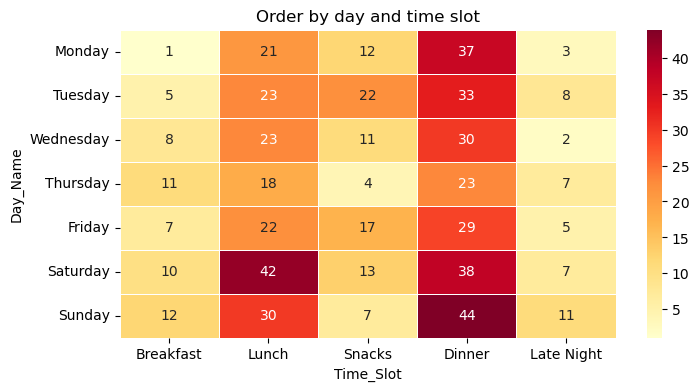

Time_Slot,Breakfast,Lunch,Snacks,Dinner,Late Night
Day_Name,,,,,
Monday,1,21,12,37,3
Tuesday,5,23,22,33,8
Wednesday,8,23,11,30,2
Thursday,11,18,4,23,7
Friday,7,22,17,29,5
Saturday,10,42,13,38,7
Sunday,12,30,7,44,11


In [81]:
plt.figure(figsize=(8,4))
sns.heatmap(e2, annot=True, fmt='d', cmap='YlOrRd', linewidths=0.5)
plt.title('Order by day and time slot')
plt.show()
e2.style.background_gradient(cmap='YlOrRd', axis=None)

# BUSINESS CONCLUSIONS 

### F1 Seasonality: Best and weakest months. Is there an Oct-Dec festive effect? (use D1, D12, E1)

### F2 Weekday vs weekend: Who orders more per day and who spends more per order? (use D3,E4)


### F3 Peak hours: When should the company keep the maximum delivery partners ready? (use D4, E2)

### F4 City performance: Best city, weakest city, and one city that needs attention with reasons. (use D5,D8, E3)

### F5 Cuisine and payment: What sells most, what sells the most per order, and what payment mode should the company promote? (use D6, D7, E6)

### F6 Delivery speed vs rating: Is there a link? What delivery time limit should the company target? (use D13, E7)

### F7 Data quality: Which problem in the raw data was the most dangerous if left uncleaned, and what would have gone wrong in the analysis?

### F8 Final summary: Give 3 recommendations for the management, each in the Observation - Reason - Action format.

 # BONUS CHALLENGE

###  Make a daily orders series and plot the 7-day rolling average (rolling(7).mean())

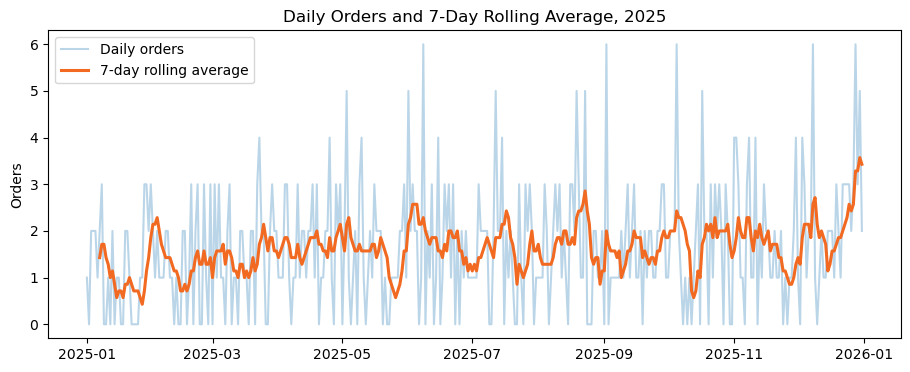

Peak 7-day average: 3.57 on 2025-12-30
Lowest 7-day average: 0.43 on 2025-01-27


In [83]:
daily = df1.groupby("Order_Date").size().reindex(pd.date_range("2025-01-01", "2025-12-31"), fill_value=0)   # days with no orders = 0
rolling7 = daily.rolling(7).mean()
plt.figure(figsize=(11, 4))
plt.plot(daily.index, daily.values, alpha=0.3, label="Daily orders")
plt.plot(rolling7.index, rolling7.values, linewidth=2.2, color="#F26A21", label="7-day rolling average")
plt.title("Daily Orders and 7-Day Rolling Average, 2025"); plt.ylabel("Orders"); plt.legend(); plt.show()
print("Peak 7-day average: %.2f on %s" % (rolling7.max(), rolling7.idxmax().date()))
print("Lowest 7-day average: %.2f on %s" % (rolling7.min(), rolling7.idxmin().date()))

### Use resample('M') after setting Order_Date as the index and compare the result with your D1 answer.

In [84]:
try:
    monthly = df1.set_index("Order_Date").resample("ME")["Final_Amount"].sum()      # pandas 2.2+
except ValueError:
    monthly = df1.set_index("Order_Date").resample("M")["Final_Amount"].sum()       # older pandas
same = np.allclose(monthly.values, d1["revenue"].values)
print("resample result equals D1 groupby result:", same)
monthly.index = monthly.index.strftime("%b"); monthly.round(0)

resample result equals D1 groupby result: True


Order_Date
Jan    11608.0
Feb    12155.0
Mar    15213.0
Apr    17399.0
May    13731.0
Jun    16581.0
Jul    16563.0
Aug    18480.0
Sep    17258.0
Oct    18785.0
Nov    18184.0
Dec    23185.0
Name: Final_Amount, dtype: float64

### • Compare Oct-Dec vs Jan-Sep: orders per day, average bill, cancellation rate.

In [85]:
df1["Season"] = np.where(df1["Month"] >= 10, "Oct-Dec", "Jan-Sep")
days = {"Oct-Dec": 92, "Jan-Sep": 273}
b3 = df1.groupby("Season").agg(orders=("Order_ID", "count"), avg_bill=("Final_Amount", "mean"),
                              cancel_rate=("Order_Status", lambda s: (s == "Cancelled").mean() * 100))
b3["orders_per_day"] = b3["orders"] / pd.Series(days)
b3.round(2)

,orders,avg_bill,cancel_rate,orders_per_day
Season,,,,
Jan-Sep,420,330.92,5.71,1.54
Oct-Dec,176,341.78,5.68,1.91


### • Plot any 3 charts (bar, line, heatmap) with proper titles and labels.

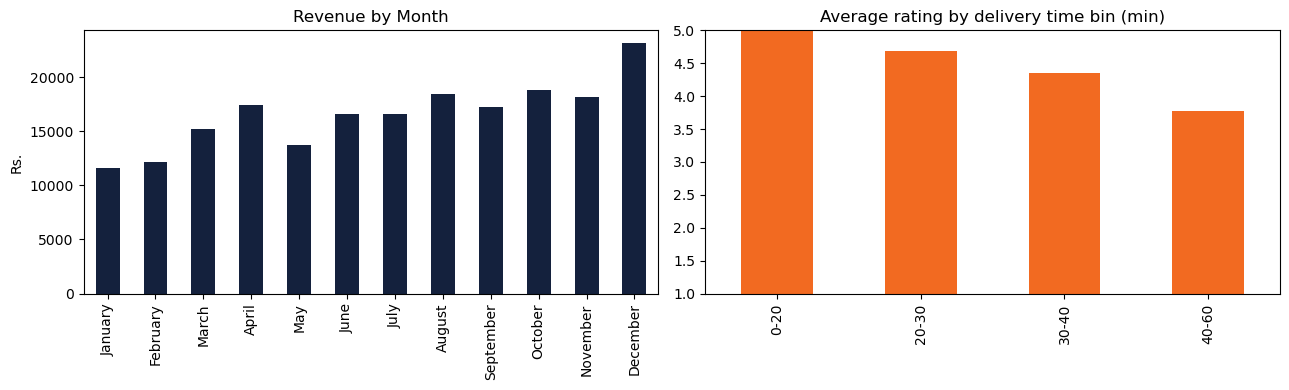

In [88]:
fig, ax=plt.subplots(1,2, figsize=(13,4))
d1['revenue'].plot(kind='bar', ax=ax[0], color='#14213D'); ax[0].set_title('Revenue by Month'); ax[0].set_ylabel('Rs.'); ax[0].set_xlabel('')
d13['avg_rating'].plot(kind='bar', ax=ax[1], color='#F26A21'); ax[1].set_title('Average rating by delivery time bin (min)'); ax[1].set_ylim(1,5); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()